In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [3]:
df = pd.read_csv("../data/raw/Online Retail.csv")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 541909
Number of columns: 8


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [6]:
df.isnull().sum().sort_values(ascending=False)

CustomerID     135080
Description      1454
StockCode           0
InvoiceNo           0
Quantity            0
InvoiceDate         0
UnitPrice           0
Country             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(5268)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


---

## 3. Data Cleaning and Preparation

- Before analyzing sales performance, we need to check the quality of the transaction data.

- We will keep the original dataset unchanged and create separate datasets for valid sales, cancelled orders, and potential returns.


In [9]:

# Keep the original dataset unchanged
raw_df = df.copy()

# Create a working copy
work_df = raw_df.copy()

# Convert InvoiceDate to datetime format
work_df["InvoiceDate"] = pd.to_datetime(
    work_df["InvoiceDate"],
    errors="coerce"
)

# Standardize invoice numbers
work_df["InvoiceNo"] = (
    work_df["InvoiceNo"].astype("string").str.strip()
)

# Identify cancelled invoices
work_df["IsCancelled"] = (
    work_df["InvoiceNo"]
    .str.upper()
    .str.startswith("C", na=False)
)

print("Original rows:", len(raw_df))
print("Working rows:", len(work_df))
print("Cancelled invoice rows:", work_df["IsCancelled"].sum())


Original rows: 541909
Working rows: 541909
Cancelled invoice rows: 9288


In [10]:
quality_checks = pd.DataFrame({
    "Issue": [
        "Missing invoice dates",
        "Cancelled invoice rows",
        "Non-positive quantities",
        "Non-positive unit prices",
        "Missing customer IDs",
        "Exact duplicate rows"
    ],
    "Count": [
        work_df["InvoiceDate"].isna().sum(),
        work_df["IsCancelled"].sum(),
        (work_df["Quantity"] <= 0).sum(),
        (work_df["UnitPrice"] <= 0).sum(),
        work_df["CustomerID"].isna().sum(),
        work_df.duplicated().sum()
    ]
})

display(quality_checks)


,Issue,Count
0,Missing invoice dates,0
1,Cancelled invoice rows,9288
2,Non-positive quantities,10624
3,Non-positive unit prices,2517
4,Missing customer IDs,135080
5,Exact duplicate rows,5268


In [11]:
# Inspect cancelled invoices
display(
    work_df.loc[
        work_df["IsCancelled"],
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice"]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
141,C536379,D,Discount,-1,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25


In [12]:
# Inspect transactions with negative quantities
display(
    work_df.loc[
        work_df["Quantity"] < 0,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice"]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
141,C536379,D,Discount,-1,27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25


In [13]:
# Inspect zero or negative prices
display(
    work_df.loc[
        work_df["UnitPrice"] <= 0,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice"]
    ].head(10)
)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
622,536414,22139,NaN,56,0.0
1970,536545,21134,NaN,1,0.0
1971,536546,22145,NaN,1,0.0
1972,536547,37509,NaN,1,0.0
1987,536549,85226A,NaN,1,0.0
1988,536550,85044,NaN,1,0.0
2024,536552,20950,NaN,1,0.0
2025,536553,37461,NaN,3,0.0
2026,536554,84670,NaN,23,0.0
2406,536589,21777,NaN,-10,0.0


In [14]:

# Keep cancelled invoices separately
cancelled_df = work_df.loc[
    work_df["IsCancelled"]
].copy()

# Identify possible returns
returns_df = work_df.loc[
    (~work_df["IsCancelled"])
    & (work_df["Quantity"] < 0)
].copy()

# Keep valid sales transactions
sales_df = work_df.loc[
    (~work_df["IsCancelled"])
    & (work_df["Quantity"] > 0)
    & (work_df["UnitPrice"] > 0)
    & (work_df["InvoiceDate"].notna())
].copy()

# Remove exact duplicate sales rows
rows_before_dedup = len(sales_df)

sales_df = sales_df.drop_duplicates().copy()

duplicates_removed = (
    rows_before_dedup - len(sales_df)
)

# Remove the helper column from the sales dataset
sales_df = sales_df.drop(columns="IsCancelled")

# Calculate transaction-line revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

print("Valid sales rows:", len(sales_df))
print("Cancelled invoice rows:", len(cancelled_df))
print("Potential return rows:", len(returns_df))
print("Duplicate sales rows removed:", duplicates_removed)


Valid sales rows: 524878
Cancelled invoice rows: 9288
Potential return rows: 1336
Duplicate sales rows removed: 5226


In [15]:

# Keep only identifiable customers for customer analysis
customer_df = sales_df.loc[
    sales_df["CustomerID"].notna()
].copy()

print("Sales rows:", len(sales_df))
print("Identifiable customer transactions:", len(customer_df))
print("Unique customers:", customer_df["CustomerID"].nunique())
print(
    "Sales rows without CustomerID:",
    sales_df["CustomerID"].isna().sum()
)


Sales rows: 524878
Identifiable customer transactions: 392692
Unique customers: 4338
Sales rows without CustomerID: 132186


In [16]:

validation = pd.DataFrame({
    "Check": [
        "Remaining duplicate rows",
        "Non-positive quantities",
        "Non-positive unit prices",
        "Missing invoice dates"
    ],
    "Count": [
        sales_df.duplicated().sum(),
        (sales_df["Quantity"] <= 0).sum(),
        (sales_df["UnitPrice"] <= 0).sum(),
        sales_df["InvoiceDate"].isna().sum()
    ]
})

display(validation)


,Check,Count
0,Remaining duplicate rows,0
1,Non-positive quantities,0
2,Non-positive unit prices,0
3,Missing invoice dates,0


In [19]:
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "sales_clean.csv"

sales_df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("Final dataset shape:", sales_df.shape)


Cleaned dataset saved to: ..\data\processed\sales_clean.csv
Final dataset shape: (524878, 9)


## 4. Sales Performance Analysis

- This section analyzes sales revenue, order volume, and product performance using the cleaned transaction data.


In [20]:

sales_df = pd.read_csv(
    "../data/processed/sales_clean.csv",
    parse_dates=["InvoiceDate"]
)

sales_df.head()


C:\Users\MYIII_M_A_505\AppData\Local\Temp\ipykernel_5136\786368970.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  sales_df = pd.read_csv(


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [21]:

total_revenue = sales_df["Revenue"].sum()

total_orders = sales_df["InvoiceNo"].nunique()

total_units_sold = sales_df["Quantity"].sum()

unique_products = sales_df["StockCode"].nunique()

average_order_value = (
    sales_df.groupby("InvoiceNo")["Revenue"]
    .sum()
    .mean()
)

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Units Sold: {total_units_sold:,}")
print(f"Unique Products Sold: {unique_products:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")


Total Revenue: £10,642,110.80
Total Orders: 19,962
Total Units Sold: 5,572,420
Unique Products Sold: 3,922
Average Order Value: £533.12


In [22]:

monthly_sales = (
    sales_df
    .assign(
        Month=sales_df["InvoiceDate"].dt.to_period("M")
    )
    .groupby("Month")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
)

monthly_sales["Month"] = (
    monthly_sales["Month"].dt.to_timestamp()
)

display(monthly_sales.head(12))


,Month,Revenue,Orders,Units_Sold
0,2010-12-01,821452.730,1559,358019
1,2011-01-01,689811.610,1086,387099
2,2011-02-01,522545.560,1100,282934
3,2011-03-01,716215.260,1454,376599
4,2011-04-01,536968.491,1246,307953
5,2011-05-01,769296.610,1681,395001
6,2011-06-01,760547.010,1533,388511
7,2011-07-01,718076.121,1476,399693
8,2011-08-01,757841.380,1361,421020
9,2011-09-01,1056435.192,1838,569573


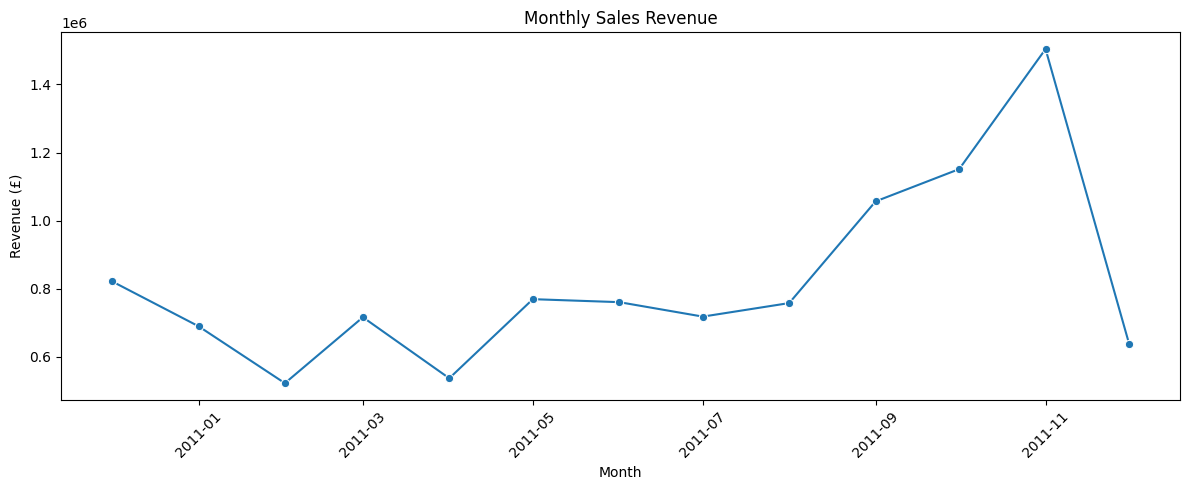

In [23]:

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [24]:

top_products = (
    sales_df
    .groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_products)


,StockCode,Description,Revenue,Units_Sold,Orders
4150,DOT,DOTCOM POSTAGE,206248.77,706,706
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
2877,47566,PARTY BUNTING,99445.23,18283,1685
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
4153,POST,POSTAGE,78101.88,3150,1126
4151,M,Manual,77750.27,6984,289
2029,23084,RABBIT NIGHT LIGHT,66870.03,30739,994


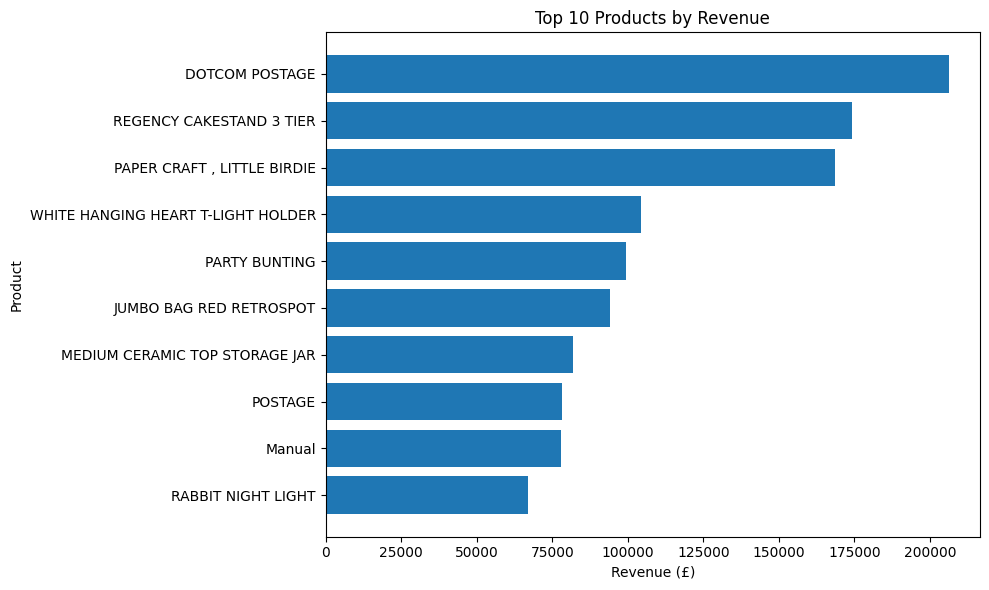

In [25]:

plot_products = top_products.sort_values("Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_products["Description"].fillna("Unknown"),
    plot_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [26]:

country_sales = (
    sales_df
    .groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

display(country_sales.head(10))


,Country,Revenue,Orders,Units_Sold
36,United Kingdom,9001744.094,18020,4646906
24,Netherlands,285446.340,94,200361
10,EIRE,283140.520,288,147007
14,Germany,228678.400,458,119154
13,France,209625.370,392,112060
0,Australia,138453.810,57,83891
31,Spain,61558.560,90,27933
33,Switzerland,57067.600,54,30617
3,Belgium,41196.340,98,23237
32,Sweden,38367.830,36,36078


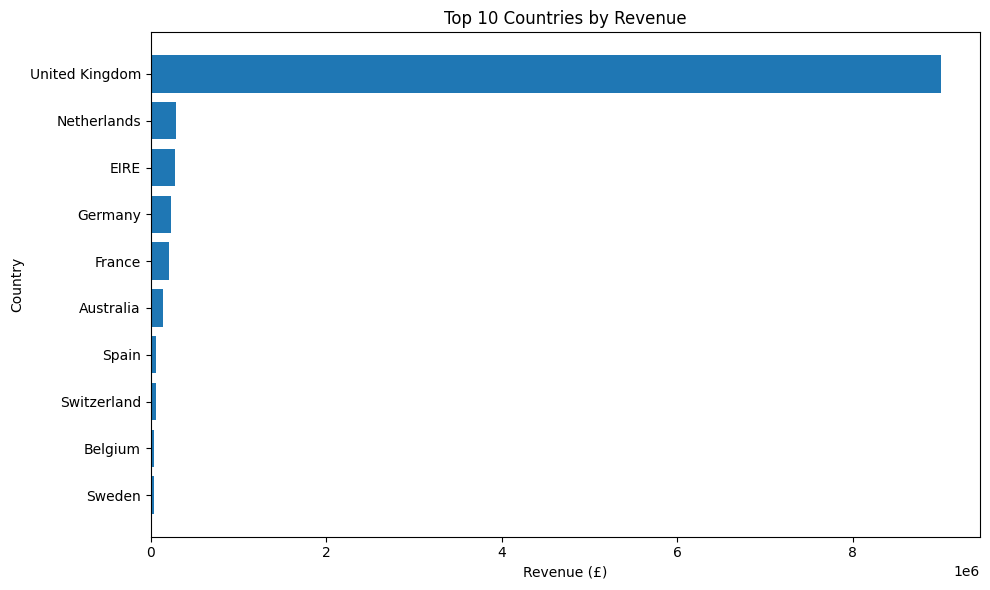

In [27]:

top_countries = (
    country_sales.head(10)
    .sort_values("Revenue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()
